In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.optimize import curve_fit

In [2]:
df = pd.read_csv("solar_system.csv")

In [3]:
print(df.shape)
print(df.head)
print(df.tail)
# There are 20 rows, and 11 columns

(20, 11)
<bound method NDFrame.head of                       Attribute Mercury    Venus  Earth   Moon   Mars  \
0                Mass (10^24kg)   0.330     4.87   5.97  0.073  0.642   
1                 Diameter (km)    4879    12104  12756   3475   6792   
2              Density (kg/m^3)    5429     5243   5514   3340   3934   
3               Gravity (m/s^2)     3.7      8.9    9.8    1.6    3.7   
4        Escape Velocity (km/s)     4.3     10.4   11.2    2.4    5.0   
5       Rotation Period (hours)  1407.6  -5832.5   23.9  655.7   24.6   
6         Length of Day (hours)  4222.6   2802.0   24.0  708.7   24.7   
7   Distance from Sun (10^6 km)    57.9    108.2  149.6  0.384  228.0   
8          Perihelion (10^6 km)    46.0    107.5  147.1  0.363  206.7   
9            Aphelion (10^6 km)    69.8    108.9  152.1  0.406  249.3   
10        Orbital Period (days)    88.0    224.7  365.2   27.3  687.0   
11      Orbital Velocity (km/s)    47.4     35.0   29.8    1.0   24.1   
12    Orbita

In [4]:
print(df.columns)
print(df.index)
# I'm assuming y'all meant index when you say row names.

Index(['Attribute', 'Mercury', 'Venus', 'Earth', 'Moon', 'Mars', 'Jupiter',
       'Saturn', 'Uranus', 'Neptune', 'Pluto'],
      dtype='str')
RangeIndex(start=0, stop=20, step=1)


In [5]:
orbital_period = df.iloc[10, 1:].astype(float)
perihelion = df.iloc[8, 1:].astype(float)
aphelion = df.iloc[9, 1:].astype(float)

The perihelion is the distance of the orbiting body from the sun at it's closest point

The aphelion is the distance of the orbiting body from the sun at it's furthest point

The semimajor axis is the overall length of the longest axis of the ellipse of an orbit

In [6]:
semi_major_axis = (perihelion + aphelion) / 2

In [7]:
new_row = pd.Series(semi_major_axis).to_frame().transpose()
df_new = pd.concat([df, new_row], ignore_index = True)
df_new.at[20, "Attribute"] = "Semi-major Axis (10^6 km)"

In [8]:
print(df_new.shape)
# 21 Rows, 11 Columns

(21, 11)


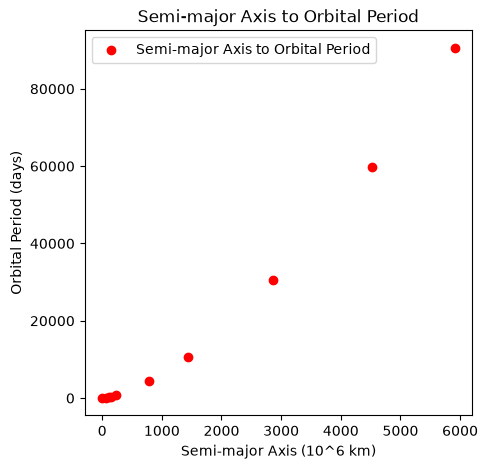

In [9]:
plt.figure(figsize=(5,5))
plt.scatter(semi_major_axis, orbital_period, color = "red", label = "Semi-major Axis to Orbital Period")
plt.xlabel("Semi-major Axis (10^6 km)")
plt.ylabel("Orbital Period (days)")
plt.title("Semi-major Axis to Orbital Period")
plt.legend()
plt.show()

In [10]:
def keplers_third_law(a,m):
    return m * a ** 1.5

In [11]:
p0 = [1]
popt, pcov = curve_fit(keplers_third_law, semi_major_axis, orbital_period, p0 = p0)
m_fit = popt

residuals = orbital_period - keplers_third_law(semi_major_axis, m_fit)
chi2 = np.sum(residuals ** 2)
dof = len(orbital_period) - len(popt)
chi2_reduced = chi2 / dof

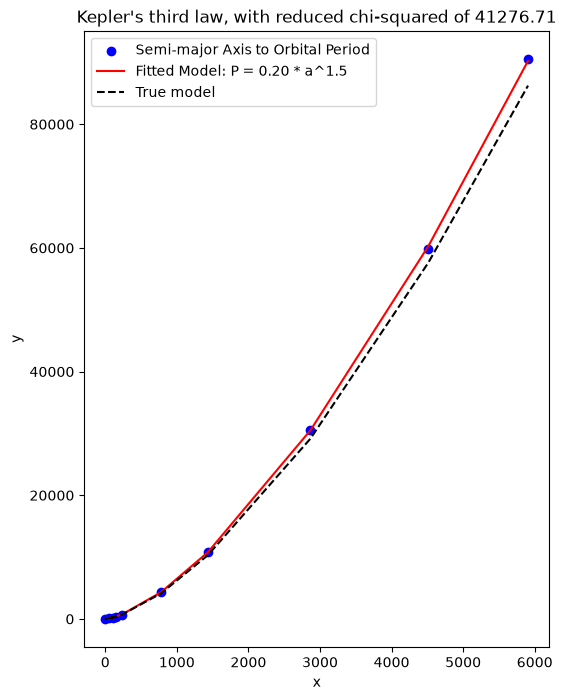

In [12]:
plt.figure(figsize = (6,8))
plt.scatter(semi_major_axis, orbital_period, color = "blue", label = "Semi-major Axis to Orbital Period")
plt.plot(semi_major_axis, keplers_third_law(semi_major_axis, m_fit), color = "red", label = f"Fitted Model: P = {m_fit.item():.2f} * a^1.5")
plt.plot(semi_major_axis, keplers_third_law(semi_major_axis, 0.19), color = "black", linestyle = "--", label = "True model")
plt.xlabel("x")
plt.ylabel("y")
plt.legend()
plt.title(f"Kepler's third law, with reduced chi-squared of {chi2_reduced:.2f}")
plt.show()

In [13]:
df_new.to_csv("kepler.csv", index = False)